In [2]:
# From Real Jan Weather Data, use LR to predict ride data for Jan
# Wieghted by past Jan ride/weather data
# Rain, Snow, Day of Week, Temp, Wind
# Verify Pred on Real Jan Ride data

In [3]:
import pandas as pd
from pathlib import Path
import numpy as np

In [4]:
#Load Data
div22=pd.read_csv(r"C:\Users\gutti\310Repo\Project3\DivvyData_Jan\202201-divvy-tripdata.csv", parse_dates=["started_at", "ended_at"])
div23=pd.read_csv(r"C:\Users\gutti\310Repo\Project3\DivvyData_Jan\202301-divvy-tripdata.csv", parse_dates=["started_at", "ended_at"])
div24=pd.read_csv(r"C:\Users\gutti\310Repo\Project3\DivvyData_Jan\202401-divvy-tripdata.csv", parse_dates=["started_at", "ended_at"])
div25=pd.read_csv(r"C:\Users\gutti\310Repo\Project3\DivvyData_Jan\202501-divvy-tripdata.csv", parse_dates=["started_at", "ended_at"])
weather22=pd.read_csv(r"C:\Users\gutti\310Repo\Project3\NN_WeatherData\weatherdata22.csv",skiprows=3)
weather23=pd.read_csv(r"C:\Users\gutti\310Repo\Project3\NN_WeatherData\weatherdata23.csv",skiprows=3)
weather24=pd.read_csv(r"C:\Users\gutti\310Repo\Project3\NN_WeatherData\weatherdata24.csv",skiprows=3)
weather25=pd.read_csv(r"C:\Users\gutti\310Repo\Project3\NN_WeatherData\weatherdata25.csv",skiprows=3)
weather26=pd.read_csv(r"C:\Users\gutti\310Repo\Project3\NN_WeatherData\weatherdata26.csv",skiprows=3)

In [5]:
#Conver Divvy to Ride Count
div22= (
    div22.groupby(div22["started_at"].dt.date)
      .size()
      .reset_index(name="ride_count")
      .rename(columns={"started_at": "date"})
)
div23= (
    div23.groupby(div23["started_at"].dt.date)
      .size()
      .reset_index(name="ride_count")
      .rename(columns={"started_at": "date"})
)
div24= (
    div24.groupby(div24["started_at"].dt.date)
      .size()
      .reset_index(name="ride_count")
      .rename(columns={"started_at": "date"})
)
div25= (
    div25.groupby(div25["started_at"].dt.date)
      .size()
      .reset_index(name="ride_count")
      .rename(columns={"started_at": "date"})
)
div25=div25.drop(index=0).reset_index(drop=True)

In [6]:
#Merge weather data to divvy and convert to one large dataset
weather25["time"] = pd.to_datetime(weather25["time"])
div25["date"] = pd.to_datetime(div25["date"])
df25 = div25.merge(weather25, left_on="date", right_on="time", how="left")
df25 = df25.drop(columns="time")

weather24["time"] = pd.to_datetime(weather24["time"])
div24["date"] = pd.to_datetime(div24["date"])
df24 = div24.merge(weather24, left_on="date", right_on="time", how="left")
df24 = df24.drop(columns="time")

weather23["time"] = pd.to_datetime(weather23["time"])
div23["date"] = pd.to_datetime(div23["date"])
df23 = div23.merge(weather23, left_on="date", right_on="time", how="left")
df23 = df23.drop(columns="time")

weather22["time"] = pd.to_datetime(weather22["time"])
div22["date"] = pd.to_datetime(div22["date"])
df22 = div22.merge(weather22, left_on="date", right_on="time", how="left")
df22 = df22.drop(columns="time")
df=pd.concat([df22,df23,df24,df25])

In [7]:
#Add days of the week and rename columns
df["date"] = pd.to_datetime(df["date"])
df["day_of_week"] = df["date"].dt.day_name()
df = df.rename(columns={
    "temperature_2m_mean (°C)": "temp_c",
    "rain_sum (mm)": "rain_mm",
    "snowfall_sum (cm)": "snow_cm",
    "wind_speed_10m_max (km/h)": "wind_kmh",
})

In [8]:
df

,date,ride_count,temp_c,rain_mm,snow_cm,wind_kmh,day_of_week
0,2022-01-01,2563,1.3,0.1,6.65,42.7,Saturday
1,2022-01-02,2062,-5.4,0.0,2.03,35.3,Sunday
2,2022-01-03,3135,-10.6,0.0,0.00,21.9,Monday
3,2022-01-04,4377,-2.8,0.0,0.00,29.6,Tuesday
4,2022-01-05,2722,-8.1,0.0,0.07,44.9,Wednesday
...,...,...,...,...,...,...,...
26,2025-01-27,6142,-1.6,0.0,0.00,25.4,Monday
27,2025-01-28,7964,2.6,0.0,0.00,27.7,Tuesday
28,2025-01-29,8676,3.4,0.0,0.00,22.4,Wednesday
29,2025-01-30,7426,3.0,16.8,0.00,20.0,Thursday


In [9]:
#Linear Regreesion Model

In [10]:
from sklearn.linear_model import LinearRegression
df = df.reset_index(drop=True)
features = ["temp_c", "rain_mm", "snow_cm", "wind_kmh", "day_of_week"]
X = pd.get_dummies(df[features], columns=["day_of_week"], drop_first=True, dtype=float)
y = df["ride_count"]
model = LinearRegression().fit(X, y)
print("Train R2:", model.score(X, y))
#Predict 2026
w26 = weather26.copy()
w26["date"] = pd.to_datetime(w26["time"])
w26 = w26.rename(columns={
    "temperature_2m_mean (°C)": "temp_c",
    "rain_sum (mm)": "rain_mm",
    "snowfall_sum (cm)": "snow_cm",
    "wind_speed_10m_max (km/h)": "wind_kmh",
})
w26 = w26[(w26["date"] >= "2026-01-01") & (w26["date"] < "2026-02-01")].reset_index(drop=True)
w26["day_of_week"] = w26["date"].dt.day_name()
X26 = pd.get_dummies(w26[features], columns=["day_of_week"], drop_first=True, dtype=float)
X26 = X26.reindex(columns=X.columns, fill_value=0)  # same columns, same order as training
w26["predicted_rides"] = np.clip(model.predict(X26), 0, None).round()
print(w26[["date", "predicted_rides"]])

Train R2: 0.748237621394849
         date  predicted_rides
0  2026-01-01           4655.0
1  2026-01-02           4559.0
2  2026-01-03           3870.0
3  2026-01-04           4125.0
4  2026-01-05           6660.0
5  2026-01-06           8039.0
6  2026-01-07           7882.0
7  2026-01-08           6978.0
8  2026-01-09           8126.0
9  2026-01-10           4484.0
10 2026-01-11           4123.0
11 2026-01-12           6105.0
12 2026-01-13           8113.0
13 2026-01-14           4906.0
14 2026-01-15           4876.0
15 2026-01-16           5499.0
16 2026-01-17           2568.0
17 2026-01-18           1970.0
18 2026-01-19           1754.0
19 2026-01-20           3993.0
20 2026-01-21           5538.0
21 2026-01-22           4834.0
22 2026-01-23            873.0
23 2026-01-24              6.0
24 2026-01-25            945.0
25 2026-01-26           1692.0
26 2026-01-27           3651.0
27 2026-01-28           3305.0
28 2026-01-29           3554.0
29 2026-01-30           3005.0
30 2026-01-

MAE: 717.8064516129032
R2:  0.8702097235475695


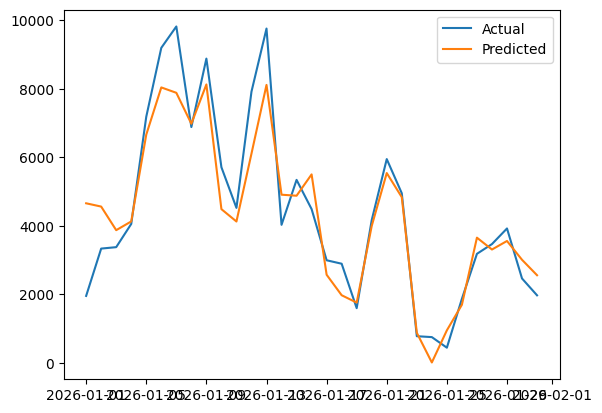

In [11]:
div26 = pd.read_csv(r"C:\Users\gutti\Downloads\202601-divvy-tripdata\202501-divvy-tripdata.csv", parse_dates=["started_at"])
actual = (div26.groupby(div26["started_at"].dt.normalize())
               .size().rename("ride_count").reset_index()
               .rename(columns={"started_at": "date"}))
actual = actual[(actual["date"] >= "2026-01-01") & (actual["date"] < "2026-02-01")]
check = w26.merge(actual, on="date")
from sklearn.metrics import mean_absolute_error, r2_score
print("MAE:", mean_absolute_error(check["ride_count"], check["predicted_rides"]))
print("R2: ", r2_score(check["ride_count"], check["predicted_rides"]))
import matplotlib.pyplot as plt
plt.plot(check["date"], check["ride_count"], label="Actual")
plt.plot(check["date"], check["predicted_rides"], label="Predicted")
plt.legend(); plt.show()

In [12]:
from scipy import stats
from sklearn.inspection import permutation_importance
n, k = X.shape
dof = n - k - 1
resid = y - model.predict(X)
sigma2 = (resid @ resid) / dof

Xd = np.column_stack([np.ones(n), X.values.astype(float)])
cov = sigma2 * np.linalg.pinv(Xd.T @ Xd)
se = np.sqrt(np.diag(cov))

params = np.r_[model.intercept_, model.coef_]
names = ["intercept"] + list(X.columns)
t_vals = params / se
p_vals = 2 * stats.t.sf(np.abs(t_vals), dof)
t_crit = stats.t.ppf(0.975, dof)

results = pd.DataFrame({
    "coef": params,
    "std_err": se,
    "t": t_vals,
    "p_value": p_vals,
    "ci_low": params - t_crit * se,
    "ci_high": params + t_crit * se,
}, index=names)
results["significant (p<0.05)"] = results["p_value"] < 0.05

print(results.round(3))
r2 = model.score(X, y)
adj_r2 = 1 - (1 - r2) * (n - 1) / dof
F = (r2 / k) / ((1 - r2) / dof)
print(f"\nR2: {r2:.3f}  Adj R2: {adj_r2:.3f}  F-test p-value: {stats.f.sf(F, k, dof):.4g}  n={n}")
perm = permutation_importance(model, X, y, n_repeats=30, random_state=0, scoring="r2")
imp = pd.DataFrame({
    "r2_drop_mean": perm.importances_mean,
    "r2_drop_std": perm.importances_std,
}, index=X.columns).sort_values("r2_drop_mean", ascending=False)
print("\nPermutation importance:")
print(imp.round(4))

                           coef  std_err       t  p_value    ci_low   ci_high  \
intercept              6775.940  479.849  14.121    0.000  5825.274  7726.607   
temp_c                  266.437   17.889  14.894    0.000   230.995   301.879   
rain_mm                -120.157   28.518  -4.213    0.000  -176.657   -63.658   
snow_cm                -336.987   67.751  -4.974    0.000  -471.214  -202.760   
wind_kmh                -20.324   15.106  -1.345    0.181   -50.253     9.604   
day_of_week_Monday     -325.676  380.996  -0.855    0.394 -1080.499   429.147   
day_of_week_Saturday  -1189.610  392.405  -3.032    0.003 -1967.036  -412.184   
day_of_week_Sunday    -1510.035  385.570  -3.916    0.000 -2273.919  -746.151   
day_of_week_Thursday    706.668  389.407   1.815    0.072   -64.817  1478.154   
day_of_week_Tuesday     555.673  380.318   1.461    0.147  -197.806  1309.152   
day_of_week_Wednesday   543.373  385.387   1.410    0.161  -220.148  1306.894   

                       sign